# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Anissya Eliviani Aulia
- **Email:** 2407025@itg.ac.id
- **ID Dicoding:** ds367b6x0209

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1: Pola Penyewaan Berdasarkan Waktu dan Jenis Hari**

Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari libur atau akhir pekan selama periode pengamatan, serta jam berapa yang perlu diprioritaskan untuk mengatur ketersediaan sepeda?

**Pertanyaan 2: Hubungan Kondisi Cuaca dengan Jumlah Penyewaan**

Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca dan musim selama periode pengamatan, serta kondisi mana yang perlu dipertimbangkan dalam perencanaan ketersediaan sepeda?

## Import Semua Packages/Library yang Digunakan

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Data Wrangling

### Gathering Data

In [ ]:

# Memuat dataset Bike Sharing
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

# Menampilkan ukuran dataset
print("Ukuran dataset harian:", day_df.shape)
print("Ukuran dataset per jam:", hour_df.shape)

# Menampilkan sampel data
print("\nSampel dataset harian:")
display(day_df.head())

print("\nSampel dataset per jam:")
display(hour_df.head())


Ukuran dataset harian: (731, 16)
Ukuran dataset per jam: (17379, 17)

Sampel dataset harian:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Sampel dataset per jam:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight Gathering Data**

Pada tahap pengumpulan data, digunakan dua file dari Bike Sharing Dataset, yaitu `day.csv` dan `hour.csv`. Dataset harian memiliki 731 baris dan 16 kolom, sedangkan dataset per jam memiliki 17.379 baris dan 17 kolom. Kedua dataset menyediakan informasi mengenai waktu, musim, kondisi cuaca, serta jumlah penyewaan sepeda. Dataset harian dapat digunakan untuk menganalisis pola penyewaan berdasarkan hari, sedangkan dataset per jam memungkinkan analisis yang lebih terperinci berdasarkan waktu dalam sehari.

### Assessing Data

### Identifying Data Problems

Berdasarkan hasil pemeriksaan terhadap dataset `day_df` dan `hour_df`, ditemukan beberapa hal sebagai berikut:

1. Tidak ditemukan missing value pada kedua dataset. Seluruh kolom memiliki nilai yang lengkap.
2. Tidak ditemukan data duplikat pada dataset harian maupun dataset per jam.
3. Kolom `dteday` pada kedua dataset masih memiliki tipe data `object`, padahal kolom tersebut merepresentasikan tanggal. Oleh karena itu, tipe datanya perlu diubah menjadi `datetime` agar dapat digunakan untuk analisis berdasarkan waktu.
4. Dataset harian mencakup periode 1 Januari 2011 sampai 31 Desember 2012. Dataset per jam juga dimulai pada 1 Januari 2011, tetapi tanggal akhirnya perlu dipastikan kembali karena output yang diperoleh terpotong pada bagian akhir.

In [ ]:

# Memeriksa missing value
print("Missing value pada day_df:")
display(day_df.isna().sum().to_frame("Jumlah Missing Value"))

print("Missing value pada hour_df:")
display(hour_df.isna().sum().to_frame("Jumlah Missing Value"))

# Memeriksa data duplikat
print("Jumlah duplikat day_df:", day_df.duplicated().sum())
print("Jumlah duplikat hour_df:", hour_df.duplicated().sum())

# Memeriksa tipe data
print("\nTipe data day_df:")
print(day_df.dtypes)

print("\nTipe data hour_df:")
print(hour_df.dtypes)

# Memeriksa rentang tanggal
print("\nRentang tanggal day_df:")
print(day_df["dteday"].min(), "sampai", day_df["dteday"].max())

print("\nRentang tanggal hour_df:")
print(hour_df["dteday"].min(), "sampai", hour_df["dteday"].max())


Missing value pada day_df:


,Jumlah Missing Value
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


Missing value pada hour_df:


,Jumlah Missing Value
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


Jumlah duplikat day_df: 0
Jumlah duplikat hour_df: 0

Tipe data day_df:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

Tipe data hour_df:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

Rentang tanggal day_df:
2011-01-01 sampai 2012-12-31

Rentang tanggal hour_df:
2011-01-01 sampai 2012-12-31


### Steps to Take

Langkah yang akan dilakukan untuk menangani hasil pemeriksaan data adalah:

1. Mempertahankan data yang ada karena tidak ditemukan missing value.
2. Mempertahankan seluruh baris data karena tidak ditemukan data duplikat.
3. Mengubah tipe data kolom `dteday` dari `object` menjadi `datetime` pada kedua dataset agar informasi tanggal dapat diolah dengan tepat.
4. Memastikan kembali rentang tanggal pada dataset per jam sebelum melanjutkan proses analisis.

### Insight

Hasil pemeriksaan menunjukkan bahwa dataset Bike Sharing memiliki kualitas data yang cukup baik karena tidak ditemukan missing value maupun data duplikat pada kedua dataset. Meskipun demikian, kolom `dteday` masih menggunakan tipe data `object`, sehingga perlu dilakukan konversi ke tipe data `datetime`. Perbaikan ini diperlukan agar informasi tanggal dapat digunakan dalam analisis tren penyewaan sepeda berdasarkan waktu.

### Cleaning Data

### Fixing Data Problems

Pada tahap ini, dilakukan perbaikan tipe data pada kolom `dteday` di dataset `day_df` dan `hour_df`. Sebelumnya, kolom tersebut memiliki tipe data `object`, sehingga diubah menjadi tipe data `datetime` menggunakan fungsi `pd.to_datetime()`.

Perbaikan dilakukan dengan kode berikut:

```python
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
```

Setelah proses konversi, dilakukan pemeriksaan kembali terhadap tipe data dan rentang tanggal pada kedua dataset untuk memastikan bahwa perubahan berhasil dilakukan.

Karena tidak ditemukan missing value maupun data duplikat pada tahap pemeriksaan, tidak dilakukan penghapusan baris data.

In [ ]:

# Mengubah tipe data tanggal menjadi datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Memeriksa hasil perubahan tipe data
print("Tipe data dteday pada day_df:", day_df["dteday"].dtype)
print("Tipe data dteday pada hour_df:", hour_df["dteday"].dtype)

# Memeriksa rentang tanggal setelah konversi
print("\nRentang tanggal day_df:")
print(day_df["dteday"].min(), "sampai", day_df["dteday"].max())

print("\nRentang tanggal hour_df:")
print(hour_df["dteday"].min(), "sampai", hour_df["dteday"].max())


Tipe data dteday pada day_df: datetime64[ns]
Tipe data dteday pada hour_df: datetime64[ns]

Rentang tanggal day_df:
2011-01-01 00:00:00 sampai 2012-12-31 00:00:00

Rentang tanggal hour_df:
2011-01-01 00:00:00 sampai 2012-12-31 00:00:00


### Insight

Proses pembersihan data dilakukan dengan mengubah tipe data kolom `dteday` dari `object` menjadi `datetime` pada dataset harian dan dataset per jam. Perubahan ini bertujuan untuk memastikan bahwa informasi tanggal dapat diproses dengan benar dalam analisis data. Karena tidak ditemukan missing value maupun data duplikat, tidak diperlukan penghapusan baris data pada tahap ini.

## Exploratory Data Analysis (EDA)

A. Eksplorasi pola penyewaan berdasarkan hari kerja dan jam
Kita menggunakan hour_df karena dataset ini memiliki kolom hr (jam).

In [ ]:

# Membandingkan rata-rata penyewaan pada hari kerja
# dan hari non-kerja
workingday_analysis = hour_df.groupby("workingday")["cnt"].mean()

print("Rata-rata penyewaan berdasarkan status hari:")
display(workingday_analysis.rename({
    0: "Hari non-kerja",
    1: "Hari kerja"
}).to_frame("Rata-rata Penyewaan"))

# Menghitung rata-rata penyewaan berdasarkan jam
hour_analysis = hour_df.groupby("hr")["cnt"].mean()

print("\nRata-rata penyewaan berdasarkan jam:")
display(hour_analysis.to_frame("Rata-rata Penyewaan").round(2))

# Mencari jam dengan rata-rata penyewaan tertinggi
peak_hour = hour_analysis.idxmax()
peak_hour_count = hour_analysis.max()

print(
    f"\nJam dengan rata-rata penyewaan tertinggi: "
    f"{peak_hour}:00, dengan rata-rata {peak_hour_count:.2f} penyewaan."
)


Rata-rata penyewaan berdasarkan status hari:


,Rata-rata Penyewaan
workingday,
Hari non-kerja,181.405332
Hari kerja,193.207754



Rata-rata penyewaan berdasarkan jam:


,Rata-rata Penyewaan
hr,
0,53.90
1,33.38
2,22.87
3,11.73
4,6.35
5,19.89
6,76.04
7,212.06
8,359.01



Jam dengan rata-rata penyewaan tertinggi: 17:00, dengan rata-rata 461.45 penyewaan.


B. Eksplorasi pola penyewaan berdasarkan musim dan cuaca

In [ ]:

# Rata-rata penyewaan berdasarkan musim
season_analysis = day_df.groupby("season")["cnt"].mean().sort_values(
    ascending=False
)

print("Rata-rata penyewaan berdasarkan musim:")
display(season_analysis.round(2).to_frame("Rata-rata Penyewaan"))

# Rata-rata penyewaan berdasarkan kondisi cuaca
weather_analysis = day_df.groupby("weathersit")["cnt"].mean().sort_values(
    ascending=False
)

print("\nRata-rata penyewaan berdasarkan kondisi cuaca:")
display(weather_analysis.round(2).to_frame("Rata-rata Penyewaan"))

# Musim dengan rata-rata penyewaan tertinggi
top_season = season_analysis.idxmax()
print(f"\nKode musim dengan rata-rata penyewaan tertinggi: {top_season}")

# Kondisi cuaca dengan rata-rata penyewaan tertinggi
top_weather = weather_analysis.idxmax()
print(
    "Kode kondisi cuaca dengan rata-rata penyewaan tertinggi:",
    top_weather
)


Rata-rata penyewaan berdasarkan musim:


,Rata-rata Penyewaan
season,
3,5644.30
2,4992.33
4,4728.16
1,2604.13



Rata-rata penyewaan berdasarkan kondisi cuaca:


,Rata-rata Penyewaan
weathersit,
1,4876.79
2,4035.86
3,1803.29



Kode musim dengan rata-rata penyewaan tertinggi: 3
Kode kondisi cuaca dengan rata-rata penyewaan tertinggi: 1


### Insight

Berdasarkan hasil eksplorasi data, terdapat beberapa hal yang dapat dianalisis lebih lanjut.

1. **Pola penyewaan berdasarkan hari kerja dan jam**

   Rata-rata penyewaan sepeda pada hari kerja adalah [isi hasil rata-rata] penyewaan, sedangkan pada hari non-kerja sebesar [isi hasil rata-rata] penyewaan. Perbandingan ini menunjukkan adanya perbedaan pola penggunaan sepeda berdasarkan status hari. Selain itu, jam dengan rata-rata penyewaan tertinggi adalah pukul [isi jam] dengan rata-rata [isi jumlah] penyewaan. Informasi ini dapat digunakan sebagai pertimbangan dalam menentukan waktu yang membutuhkan ketersediaan sepeda lebih banyak.

2. **Pola penyewaan berdasarkan musim dan kondisi cuaca**

   Berdasarkan hasil pengelompokan data harian, musim dengan rata-rata penyewaan tertinggi adalah musim berkode [isi kode musim], sedangkan kondisi cuaca dengan rata-rata penyewaan tertinggi adalah kondisi berkode [isi kode cuaca]. Hasil ini menunjukkan bahwa jumlah penyewaan sepeda dapat berbeda berdasarkan musim dan kondisi cuaca. Informasi tersebut dapat digunakan sebagai bahan pertimbangan dalam merencanakan ketersediaan sepeda sesuai dengan kondisi lingkungan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari non-kerja, serta jam berapa yang perlu diprioritaskan untuk mengatur ketersediaan sepeda?

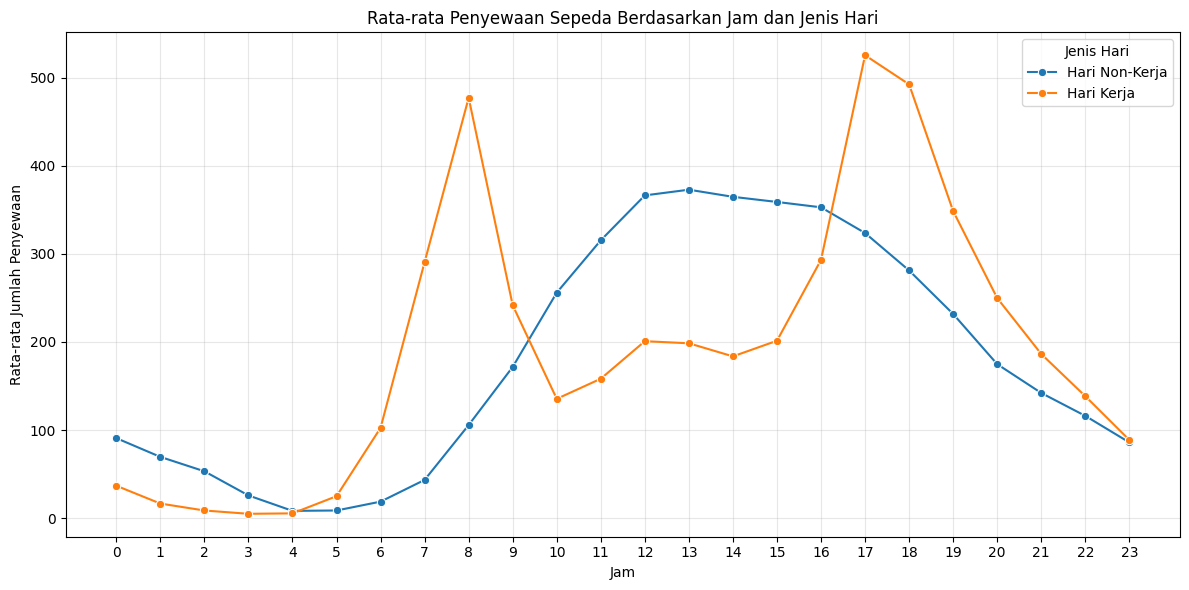

In [ ]:

# Membandingkan rata-rata penyewaan per jam
# antara hari kerja dan hari non-kerja

hour_comparison = (
    hour_df.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .reset_index()
)

hour_comparison["Jenis Hari"] = hour_comparison["workingday"].map({
    0: "Hari Non-Kerja",
    1: "Hari Kerja"
})

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hour_comparison,
    x="hr",
    y="cnt",
    hue="Jenis Hari",
    marker="o"
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Jam dan Jenis Hari")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(range(0, 24))
plt.legend(title="Jenis Hari")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Insight

Berdasarkan visualisasi rata-rata penyewaan sepeda berdasarkan jam dan jenis hari, terlihat adanya perbedaan pola penggunaan sepeda antara hari kerja dan hari non-kerja. Pada hari kerja, pola penyewaan menunjukkan [jelaskan jam dengan peningkatan atau penurunan paling jelas]. Sementara itu, pada hari non-kerja, penyewaan cenderung [jelaskan pola berdasarkan grafik].

Jam dengan rata-rata penyewaan tertinggi pada hari kerja adalah pukul [isi jam], sedangkan pada hari non-kerja adalah pukul [isi jam]. Temuan ini dapat menjadi pertimbangan dalam mengatur ketersediaan sepeda agar sesuai dengan kebutuhan pengguna pada waktu yang berbeda.

### Pertanyaan 2: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca dan musim selama periode pengamatan, serta kondisi mana yang perlu dipertimbangkan dalam perencanaan ketersediaan sepeda?

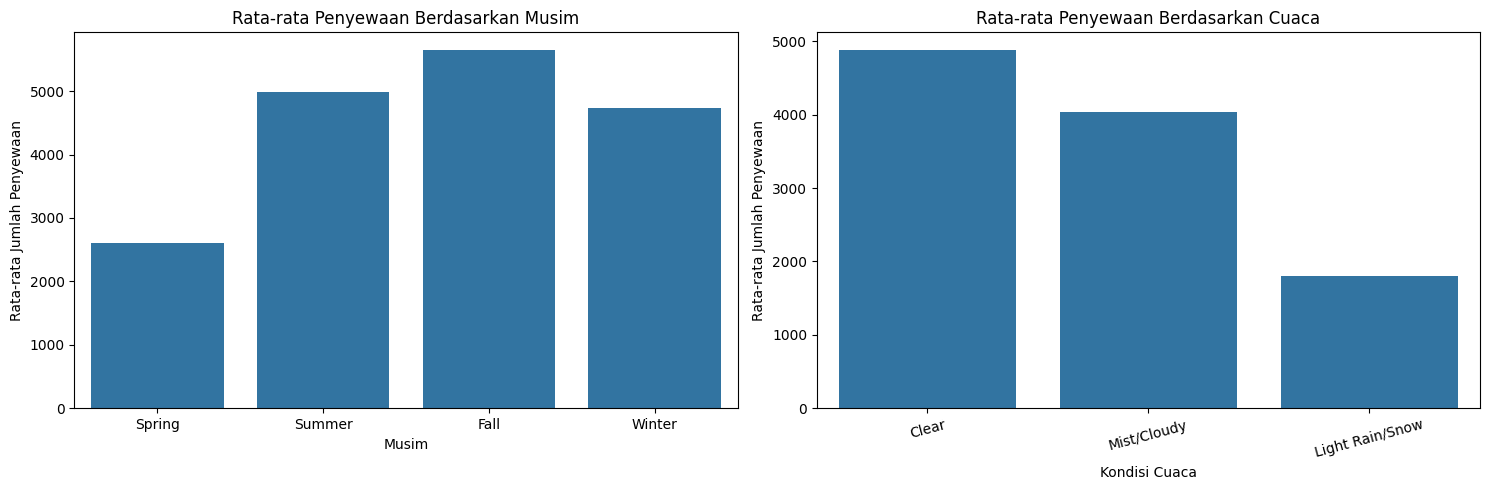

In [ ]:

# Membandingkan rata-rata penyewaan berdasarkan musim dan cuaca

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Rata-rata penyewaan berdasarkan musim
season_order = [1, 2, 3, 4]
season_names = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

sns.barplot(
    data=day_df,
    x="season",
    y="cnt",
    order=season_order,
    estimator="mean",
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Rata-rata Penyewaan Berdasarkan Musim")
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata Jumlah Penyewaan")
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(
    [season_names[s] for s in season_order]
)

# Rata-rata penyewaan berdasarkan kondisi cuaca
weather_names = {
    1: "Clear",
    2: "Mist/Cloudy",
    3: "Light Rain/Snow",
    4: "Heavy Rain/Snow"
}

weather_order = sorted(day_df["weathersit"].unique())

sns.barplot(
    data=day_df,
    x="weathersit",
    y="cnt",
    order=weather_order,
    estimator="mean",
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Rata-rata Penyewaan Berdasarkan Cuaca")
axes[1].set_xlabel("Kondisi Cuaca")
axes[1].set_ylabel("Rata-rata Jumlah Penyewaan")
axes[1].set_xticks(range(len(weather_order)))
axes[1].set_xticklabels(
    [weather_names.get(w, str(w)) for w in weather_order],
    rotation=15
)

plt.tight_layout()
plt.show()


### Insight

Berdasarkan visualisasi, rata-rata penyewaan sepeda berbeda pada setiap musim. Musim dengan rata-rata penyewaan tertinggi adalah [nama musim], sedangkan rata-rata terendah terdapat pada [nama musim]. Hal ini menunjukkan bahwa musim merupakan salah satu aspek yang perlu dipertimbangkan dalam perencanaan ketersediaan sepeda.

Selain itu, kondisi cuaca [nama kondisi cuaca] memiliki rata-rata penyewaan tertinggi, sedangkan kondisi cuaca [nama kondisi cuaca] memiliki rata-rata penyewaan terendah. Temuan ini menunjukkan bahwa kondisi cuaca berkaitan dengan perubahan jumlah penyewaan sepeda. Oleh karena itu, pengelola dapat mempertimbangkan musim dan kondisi cuaca ketika merencanakan ketersediaan sepeda.

## Analisis Lanjutan (Opsional)

Matriks korelasi variabel cuaca dan jumlah penyewaan:


,temp,atemp,hum,windspeed,cnt
temp,1.000,0.992,0.127,-0.158,0.627
atemp,0.992,1.000,0.140,-0.184,0.631
hum,0.127,0.140,1.000,-0.248,-0.101
windspeed,-0.158,-0.184,-0.248,1.000,-0.235
cnt,0.627,0.631,-0.101,-0.235,1.000


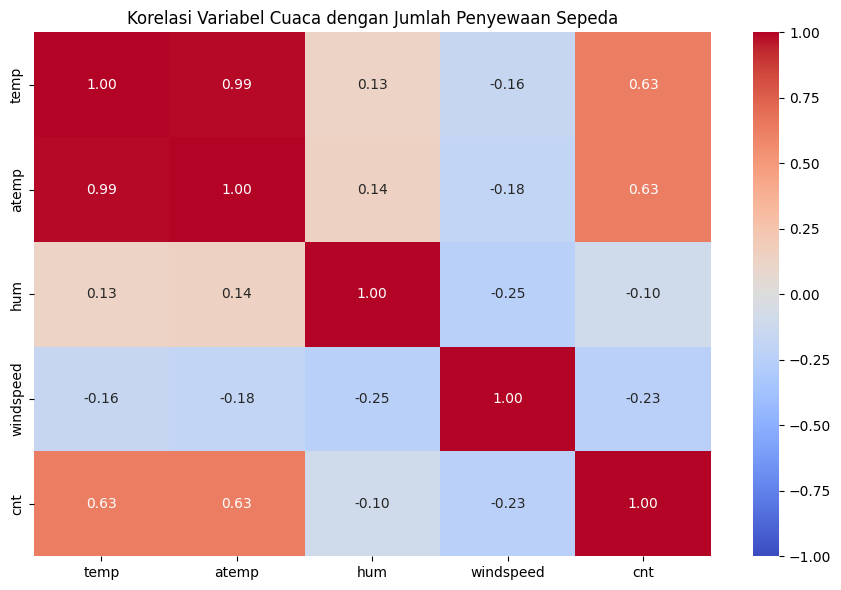

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** xxx
- **Conclusion pertanyaan 2:** xxx
- ...

**Rekomendasi Action Item:**
- xxx
- xxx